# Siêu phẳng phân chia và lề cực đại (mục 7.1.1, 7.1.2)

(a) nhiều đường thẳng cùng phân chia đúng, (b) siêu phẳng có lề lớn nhất và các vector hỗ trợ

In [1]:
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from sklearn.svm import SVC

IMAGES = Path('.')   # thư mục images/ (notebook chạy trong images/)

Cùng dữ liệu 8 điểm với codes/01, codes/02

In [2]:
X = np.array([[3, 1], [3, -1], [6, 1], [6, -1],
              [1, 0], [0, 1], [0, -1], [-1, 0]], dtype=float)
y = np.array([1, 1, 1, 1, -1, -1, -1, -1])
svm = SVC(kernel='linear', C=1e6).fit(X, y)
w, b = svm.coef_[0], svm.intercept_[0]

def draw_points(ax):
    ax.scatter(X[y == 1, 0], X[y == 1, 1], marker='s', s=70, color='#1F77B4', label='Lớp +1', zorder=3)
    ax.scatter(X[y == -1, 0], X[y == -1, 1], marker='o', s=70, color='#D62728', label='Lớp −1', zorder=3)
    ax.set_xlim(-2, 7); ax.set_ylim(-3, 3); ax.set_aspect('equal')
    ax.set_xlabel('$x_1$'); ax.set_ylabel('$x_2$')

Vẽ hình và lưu ảnh.

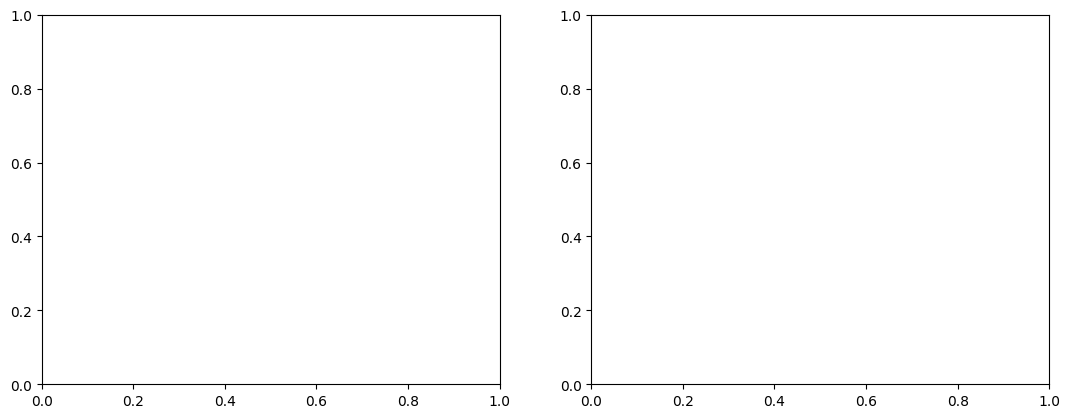

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))

(a) nhiều siêu phẳng phân chia đúng

In [4]:
draw_points(axes[0])
x_line = np.linspace(-2, 7, 2)
for slope, intercept, name in [(None, 1.5, '$L_1$'), (-1 / 0.3, 2 / 0.3, '$L_2$'), (2.0, -4.0, '$L_3$')]:
    if slope is None:
        axes[0].axvline(intercept, color='gray', lw=1.2)
        axes[0].text(intercept + 0.1, 2.6, name)
    else:
        axes[0].plot(x_line, slope * x_line + intercept, color='gray', lw=1.2)
axes[0].text(1.25, -2.8, '$L_2$'); axes[0].text(3.3, 2.6, '$L_3$')
axes[0].set_title('(a) Nhiều đường thẳng cùng phân chia đúng hai lớp')
axes[0].legend(loc='lower right', fontsize=9)

(b) lề cực đại

In [5]:
draw_points(axes[1])
for level, style, label in [(0, '-', '$\\mathbf{w}^T\\mathbf{x} + b = 0$'), (1, '--', '$\\mathbf{w}^T\\mathbf{x} + b = 1$'),
                            (-1, '--', '$\\mathbf{w}^T\\mathbf{x} + b = -1$')]:
    x0 = (level - b) / w[0]                 # w2 = 0 nên các siêu phẳng là đường thẳng đứng
    axes[1].axvline(x0, color='k', ls=style, lw=1.3)
    axes[1].text(x0 + 0.08, -2.85 if level == 0 else 2.55, label, fontsize=9)
axes[1].axvspan((-1 - b) / w[0], (1 - b) / w[0], color='#FFE8A3', alpha=0.5, zorder=0)
axes[1].scatter(*svm.support_vectors_.T, s=300, facecolors='none', edgecolors='k', lw=1.3, label='Vector hỗ trợ')
axes[1].annotate('', xy=(3, -2.1), xytext=(1, -2.1), arrowprops=dict(arrowstyle='<->', lw=1.2))
axes[1].text(2, -1.95, 'lề $= 2/\\|\\mathbf{w}\\| = %.0f$' % (2 / np.linalg.norm(w)), ha='center', fontsize=9)
axes[1].annotate('', xy=(2.8, 1.8), xytext=(2, 1.8), arrowprops=dict(arrowstyle='->', lw=1.5, color='green'))
axes[1].text(2.85, 1.7, '$\\mathbf{w}$', color='green')
axes[1].set_title('(b) SVM: siêu phẳng có lề lớn nhất')
axes[1].legend(loc='lower right', fontsize=9)
fig.tight_layout()
fig.savefig(IMAGES / 'max_margin.png', dpi=150)